# Exercício – Ciência de Dados aplicada a um problema real
## Faltas e horas de estudo: o que mais pesa na nota final?

**Aluno(a):** _preencher_  **RA:** _preencher_

## Parte 1 – Problema real escolhido e por que ele importa

Na faculdade, é comum ouvir que "quem falta muito reprova". Mas isso é verdade ou só impressão?
E as **horas de estudo fora da aula** – fazem diferença?

**Pergunta do problema:** em uma turma, a **frequência** e as **horas de estudo semanais** estão relacionadas à **nota final**?
Existe diferença de nota entre quem tem frequência **≥ 75%** (mínimo exigido) e quem fica abaixo disso?

**Por que importa:** se a relação existir, a coordenação pode criar alertas precoces para alunos com muitas faltas
(antes da reprovação), e os próprios alunos conseguem ver, com números, o efeito de faltar ou estudar pouco.

## Parte 2 – Dados usados e aulas/conceitos aplicados

**Origem dos dados:** dados **fictícios, mas coerentes**, de uma turma de 20 alunos (permitido pelo enunciado).
Cada linha é um aluno com: `frequencia` (%), `horas_estudo` (horas por semana) e `nota` (0 a 10).
Propositalmente, a planilha veio com **2 problemas de qualidade** (um valor faltando e um valor impossível), como acontece na vida real.

| Aula | Conceito usado | Onde aparece |
|---|---|---|
| **Aula 02 – Python** | Pandas: criar DataFrame, filtrar, agrupar | Partes 3.1 a 3.4 |
| **Aula 03 – Estatística Descritiva** | Média, mediana, desvio padrão, correlação | Parte 3.3 |
| **Aula 06 – Visualização** | Gráfico de dispersão e de barras | Parte 3.4 |
| **Aula 08 – Ética/Qualidade de Dados** | Valor ausente, valor inválido, anonimização (sem nomes) | Parte 3.2 |

## Parte 3 – Desenvolvimento da solução
### 3.1 Carregando os dados (Aula 02 – Python)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Alunos identificados só por código (sem nome) -> cuidado ético com dados pessoais (Aula 08)
dados = {
    "aluno":        [f"A{i:02d}" for i in range(1, 21)],
    "frequencia":   [95, 88, 60, 92, 70, 100, 55, 85, 78, 65, 90, 98, 72, 50, 80, None, 96, 68, 84, 150],
    "horas_estudo": [ 6,  5,  2,  7,  3,   8,  1,  4,  4,  2,  5,  9,  3,  1,  6,  4,   7,  2,  5,  6],
    "nota":         [8.5, 7.8, 4.5, 8.9, 5.5, 9.6, 3.8, 7.0, 6.8, 5.0, 8.0, 9.8, 6.0, 3.2, 7.5, 6.9, 9.0, 4.8, 7.2, 8.1],
}
df = pd.DataFrame(dados)
df

,aluno,frequencia,horas_estudo,nota
0,A01,95.0,6,8.5
1,A02,88.0,5,7.8
2,A03,60.0,2,4.5
3,A04,92.0,7,8.9
4,A05,70.0,3,5.5
5,A06,100.0,8,9.6
6,A07,55.0,1,3.8
7,A08,85.0,4,7.0
8,A09,78.0,4,6.8
9,A10,65.0,2,5.0


### 3.2 Qualidade dos dados (Aula 08 – Qualidade de Dados)
Antes de calcular qualquer coisa, verifico se os dados fazem sentido:
- **Valor ausente:** algum campo vazio?
- **Valor inválido:** frequência precisa estar entre 0 e 100%.

In [2]:
print("Valores ausentes por coluna:")
print(df.isna().sum())

invalidos = df[(df["frequencia"] < 0) | (df["frequencia"] > 100)]
print("\nFrequências impossíveis (fora de 0–100%):")
print(invalidos)

Valores ausentes por coluna:
aluno           0
frequencia      1
horas_estudo    0
nota            0
dtype: int64

Frequências impossíveis (fora de 0–100%):
   aluno  frequencia  horas_estudo  nota
19   A20       150.0             6   8.1


**Decisão:** o aluno A16 (frequência vazia) e o aluno A20 (frequência = 150%, provável erro de digitação)
são **removidos** da análise. Não invento valores para eles, porque "chutar" uma frequência poderia distorcer o resultado.
Fico com 18 alunos – poucos dados, mas confiáveis.

In [3]:
df_limpo = df.dropna()
df_limpo = df_limpo[df_limpo["frequencia"].between(0, 100)].copy()
print(f"Antes: {len(df)} alunos | Depois da limpeza: {len(df_limpo)} alunos")

Antes: 20 alunos | Depois da limpeza: 18 alunos


### 3.3 Estatística descritiva e correlação (Aula 03 – Estatística Descritiva)

In [4]:
df_limpo[["frequencia", "horas_estudo", "nota"]].describe().round(2)

,frequencia,horas_estudo,nota
count,18.00,18.00,18.00
mean,79.22,4.44,6.83
std,15.35,2.41,2.01
min,50.00,1.00,3.20
25%,68.50,2.25,5.12
50%,82.00,4.50,7.10
75%,91.50,6.00,8.38
max,100.00,9.00,9.80


In [5]:
# Correlação de Pearson: vai de -1 a +1. Perto de +1 = quando um sobe, o outro também sobe.
print("Correlação frequência x nota:  ", round(df_limpo["frequencia"].corr(df_limpo["nota"]), 2))
print("Correlação horas_estudo x nota:", round(df_limpo["horas_estudo"].corr(df_limpo["nota"]), 2))

Correlação frequência x nota:   0.99
Correlação horas_estudo x nota: 0.98


In [6]:
# Comparando grupos: frequência >= 75% (mínimo exigido) vs < 75%
df_limpo["grupo"] = df_limpo["frequencia"].apply(lambda f: ">= 75%" if f >= 75 else "< 75%")
resumo = df_limpo.groupby("grupo")["nota"].agg(["count", "mean", "median"]).round(2)
resumo

,count,mean,median
grupo,,,
< 75%,7,4.69,4.8
>= 75%,11,8.19,8.0


### 3.4 Visualização (Aula 06 – Visualização)

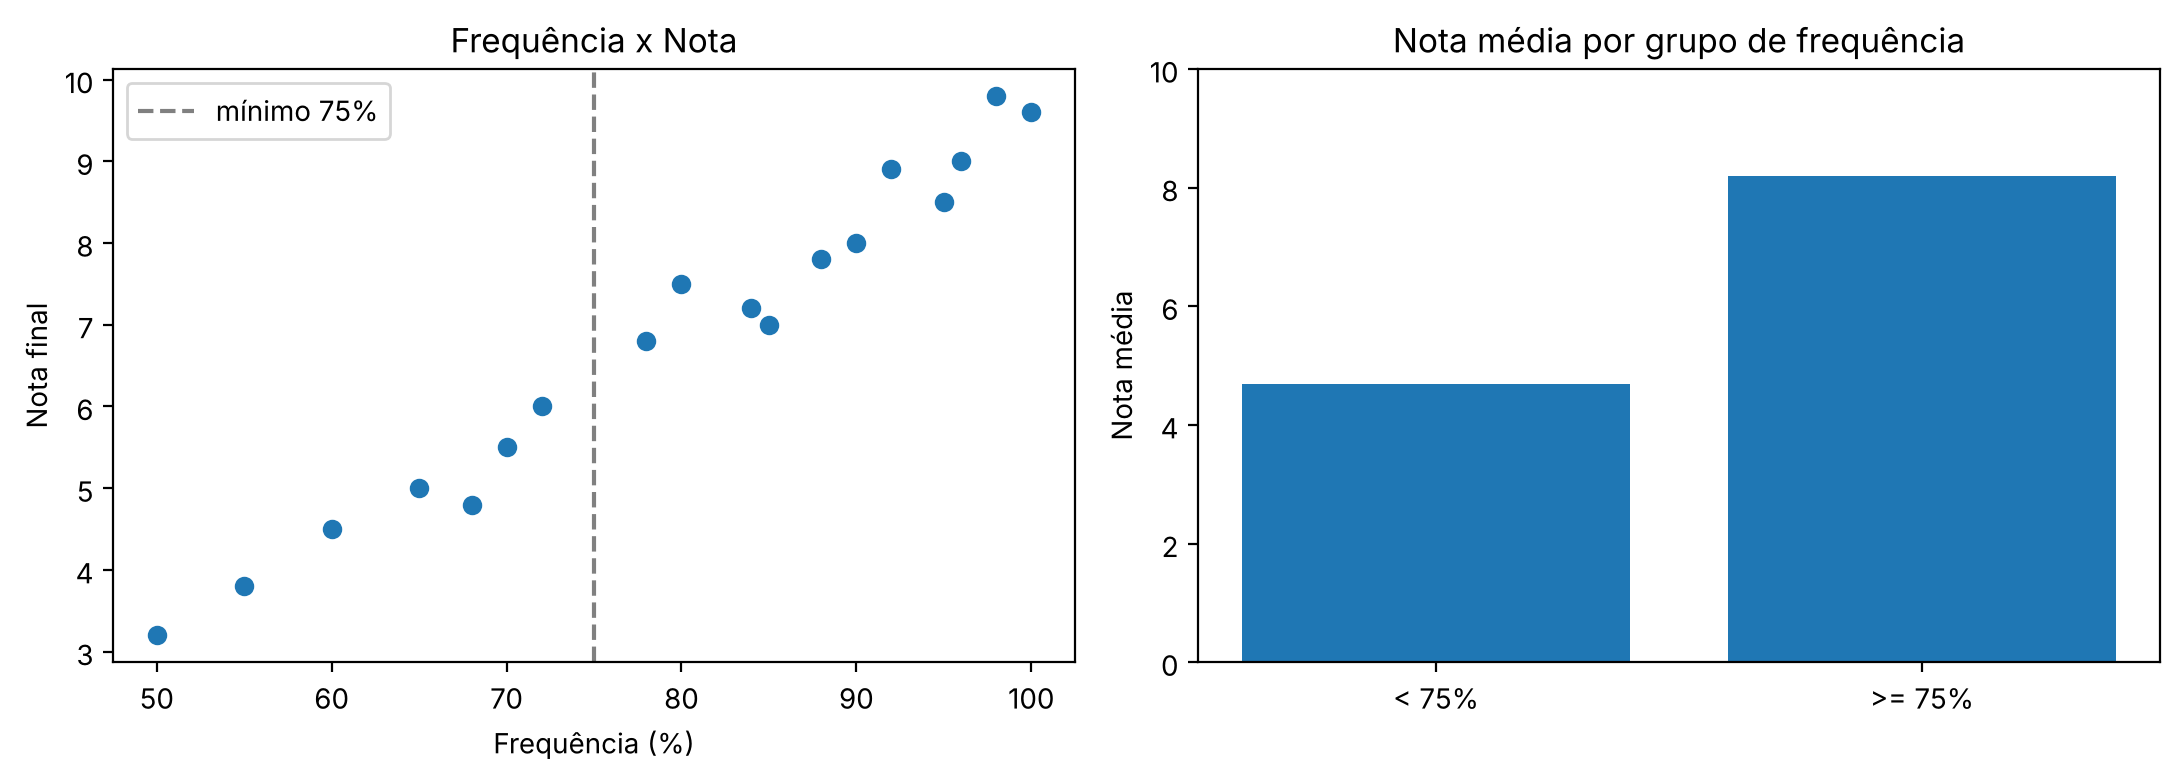

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(df_limpo["frequencia"], df_limpo["nota"])
ax[0].axvline(75, linestyle="--", color="gray", label="mínimo 75%")
ax[0].set_xlabel("Frequência (%)")
ax[0].set_ylabel("Nota final")
ax[0].set_title("Frequência x Nota")
ax[0].legend()

ax[1].bar(resumo.index, resumo["mean"])
ax[1].set_ylabel("Nota média")
ax[1].set_title("Nota média por grupo de frequência")
ax[1].set_ylim(0, 10)

plt.tight_layout()
plt.show()

**Leitura dos resultados:**
- A correlação entre frequência e nota é **forte e positiva** (cerca de 0,99 – bem alta porque os dados são fictícios; em dados reais esperaria algo menor): quem frequenta mais, em geral, tira nota maior.
- Horas de estudo também têm correlação forte com a nota (cerca de 0,98).
- O grupo com frequência ≥ 75% tem nota média 8,19 contra 4,69 do grupo abaixo de 75%.
- **Cuidado:** correlação **não prova causa**. Pode ser que alunos mais engajados faltem menos *e* estudem mais – o engajamento seria a causa comum.

## Parte 4 – Registro do uso de IA

**Ferramenta usada:** Claude (Anthropic)

**Prompt (o que eu pedi):**
> "Como resolver [enunciado do exercício enviado como print]? Gere um arquivo em ipynb."

**Resposta da IA (resumo):** a IA sugeriu o tema "frequência/horas de estudo x nota", criou um conjunto de dados fictícios
com 20 alunos (incluindo 2 erros de qualidade de propósito), montou o código em Pandas para limpeza, estatística descritiva,
correlação, comparação de grupos e gráficos, e organizou o notebook nas 6 partes pedidas.

**O que eu corrigi / completei / rejeitei e por quê:**
_(preencher com o que VOCÊ realmente revisou – exemplos de verificação que você pode fazer e descrever:)_
- _Conferi se os números da tabela `describe()` batem fazendo a média de algumas notas na mão/calculadora._
- _Verifiquei que a IA tinha colocado `frequencia = 150`, que é impossível, e confirmei que o código remove esse aluno._
- _Questionei se a correlação alta significava causa – e mantive o aviso de que correlação não é causalidade._
- _Se mudou algum dado, gráfico, texto ou tema, descreva aqui o que mudou e por quê._

## Parte 5 – Resposta à pergunta obrigatória (SEM IA)

> ⚠️ Esta parte deve ser escrita **por você, com suas palavras**, conforme exige o enunciado. A IA não escreveu esta resposta.

**Roteiro para responder:**
1. Qual foi a principal técnica/conceito? (ex.: correlação, ou limpeza de dados)
2. Por que ela resolve o problema escolhido?
3. Seu nível (iniciante / intermediário / avançado) + **um pequeno exemplo prático** que prove isso
   (ex.: explicar o que significaria uma correlação de −0,8 entre faltas e nota).
4. Um ponto em que você questionou/corrigiu a IA e como percebeu.

_Sua resposta:_

## Parte 6 – Conclusão

Com dados simples (18 alunos válidos, 3 colunas), foi possível mostrar que:
- **Frequência e horas de estudo andam juntas com notas maiores**, e alunos abaixo de 75% de frequência tiveram nota média bem menor.
- **Limpar os dados antes** foi essencial: se o aluno com 150% de frequência entrasse, o gráfico e as médias ficariam distorcidos.
- **Para o problema real:** a coordenação poderia acompanhar a frequência ao longo do semestre e avisar alunos que se aproximam de 75%,
  antes que a nota seja afetada. Como correlação não prova causa, o ideal seria acompanhar uma turma real por mais tempo para confirmar.